In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load cleaned geographical datasets

water = gpd.read_file(
    "../data/processed/patiala_water_drainage_cleaned.geojson"
)

roads = gpd.read_file(
    "../data/processed/patiala_roads_cleaned.geojson"
)

buildings = gpd.read_file(
    "../data/processed/patiala_buildings_cleaned.geojson"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("WATER AND DRAINAGE")
print("Shape:", water.shape)
display(water.head())

print("\nROADS")
print("Shape:", roads.shape)
display(roads.head())

print("\nBUILDINGS")
print("Shape:", buildings.shape)
display(buildings.head())

WATER AND DRAINAGE
Shape: (11, 9)


,id,@id,layer,tunnel,waterway,feature_category,source,length_m_approx,geometry
0,way/570505044,way/570505044,NaN,NaN,stream,stream,OpenStreetMap,4105.70,"LINESTRING (76.41022 30.34304, 76.41033 30.343..."
1,way/570506861,way/570506861,NaN,NaN,canal,canal,OpenStreetMap,680.53,"LINESTRING (76.40736 30.31923, 76.40731 30.319..."
2,way/570509678,way/570509678,NaN,NaN,canal,canal,OpenStreetMap,1349.42,"LINESTRING (76.40736 30.31923, 76.40739 30.319..."
3,way/635411807,way/635411807,NaN,NaN,stream,stream,OpenStreetMap,24836.94,"LINESTRING (76.4321 30.39558, 76.43185 30.3953..."
4,way/636369748,way/636369748,NaN,NaN,canal,canal,OpenStreetMap,5821.46,"LINESTRING (76.40171 30.31836, 76.4017 30.3182..."



ROADS
Shape: (8609, 35)


,id,@id,access,alt_name,bicycle,bridge,covered,crossing,crossing:markings,foot,...,ref:old,service,surface,tunnel,wikidata,feature_category,road_type,source,length_m_approx,geometry
0,way/42021144,way/42021144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,collector_road,tertiary,OpenStreetMap,6581.91,"LINESTRING (76.33668 30.26762, 76.33845 30.268..."
1,way/42021151,way/42021151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,collector_road,tertiary,OpenStreetMap,805.35,"LINESTRING (76.4013 30.32408, 76.40168 30.3236..."
2,way/43783504,way/43783504,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,paving_stones,NaN,NaN,local_road,residential,OpenStreetMap,280.83,"LINESTRING (76.40087 30.3409, 76.40104 30.3407..."
3,way/43810443,way/43810443,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,major_road,secondary,OpenStreetMap,605.48,"LINESTRING (76.39884 30.32165, 76.39812 30.320..."
4,way/43813121,way/43813121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,local_road,unclassified,OpenStreetMap,187.02,"LINESTRING (76.39603 30.33389, 76.39621 30.333..."



BUILDINGS
Shape: (5547, 72)


,id,@id,addr:city,addr:city:pa,addr:district,addr:full,addr:housenumber,addr:place,addr:place:pa,addr:postcode,...,tourism,type,website,wheelchair,wikidata,feature_category,building_type,source,area_m2_approx,geometry
0,relation/5935182,relation/5935182,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,multipolygon,NaN,NaN,NaN,building,university,OpenStreetMap,1031.82,"POLYGON ((76.37213 30.35333, 76.37228 30.35324..."
1,relation/5935183,relation/5935183,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,multipolygon,NaN,NaN,NaN,building,university,OpenStreetMap,1318.74,"POLYGON ((76.37221 30.35409, 76.37218 30.35409..."
2,relation/5935496,relation/5935496,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,hostel,multipolygon,NaN,NaN,NaN,building,yes,OpenStreetMap,2333.81,"POLYGON ((76.36736 30.35478, 76.36807 30.35487..."
3,relation/5958284,relation/5958284,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,hostel,multipolygon,NaN,NaN,NaN,building,yes,OpenStreetMap,4578.72,"POLYGON ((76.36277 30.35194, 76.36276 30.35177..."
4,relation/5958285,relation/5958285,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,hostel,multipolygon,NaN,NaN,NaN,building,yes,OpenStreetMap,6218.69,"POLYGON ((76.36071 30.3516, 76.36071 30.35153,..."


In [4]:
datasets = {
    "Water and Drainage": water,
    "Roads": roads,
    "Buildings": buildings
}

for name, gdf in datasets.items():

    print("\n", name)
    print("CRS:", gdf.crs)

    print("\nGeometry types:")
    print(gdf.geom_type.value_counts())

    print("\nMissing values:")
    print(gdf.isnull().sum())

    print("\nInvalid geometries:",
          (~gdf.geometry.is_valid).sum())


 Water and Drainage
CRS: EPSG:4326

Geometry types:
LineString    11
Name: count, dtype: int64

Missing values:
id                   0
@id                  0
layer               10
tunnel              10
waterway             0
feature_category     0
source               0
length_m_approx      0
geometry             0
dtype: int64

Invalid geometries: 0

 Roads
CRS: EPSG:4326

Geometry types:
LineString    8609
Name: count, dtype: int64

Missing values:
id                            0
@id                           0
access                     8511
alt_name                   8601
bicycle                    8559
bridge                     8505
covered                    8595
crossing                   8608
crossing:markings          8608
foot                       8567
footway                    8608
highway                       0
horse                      8565
incline                    8605
junction                   8597
lane_markings              8594
lanes                      856

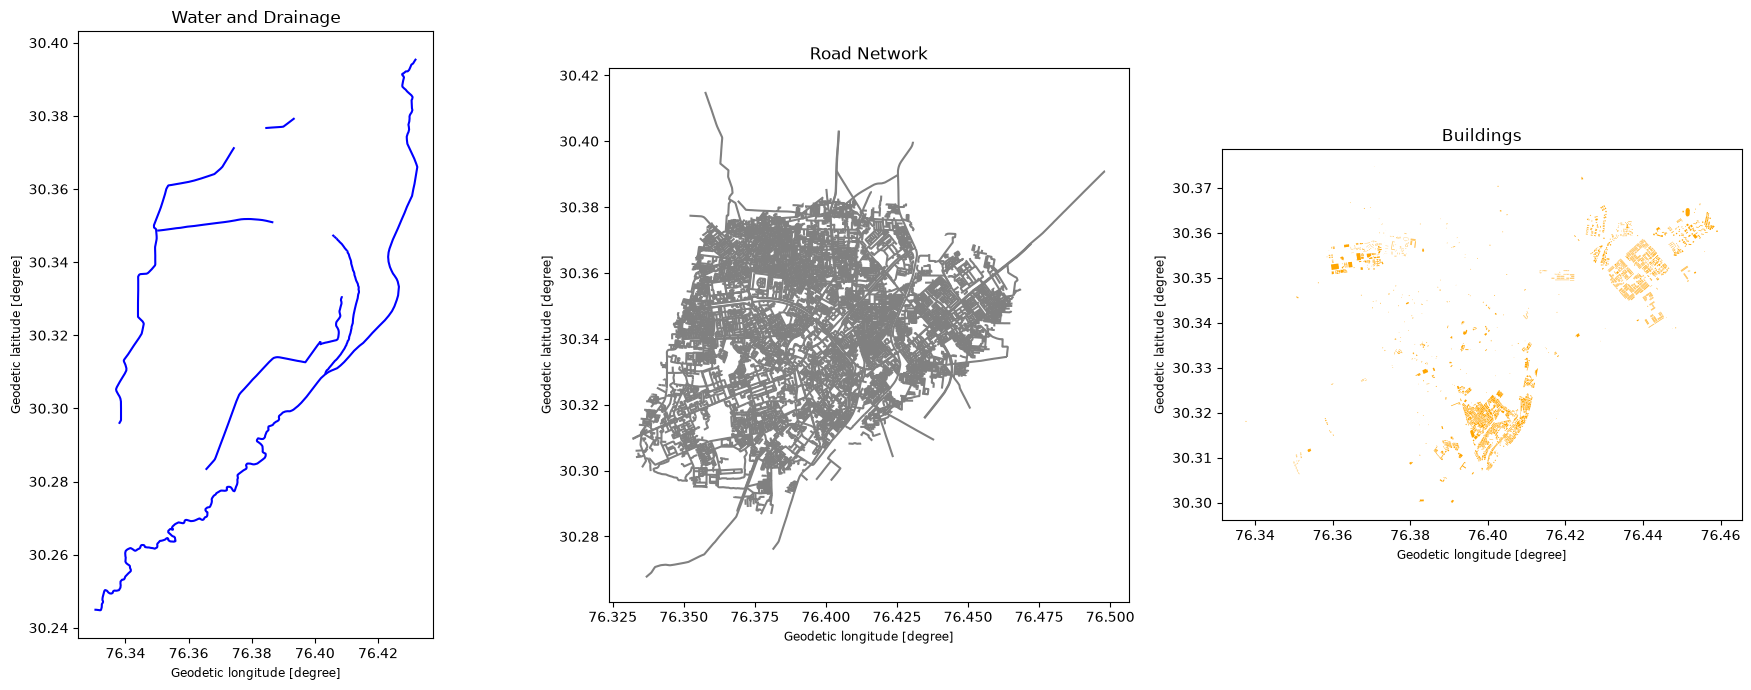

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

water.plot(ax=axes[0], color="blue")
axes[0].set_title("Water and Drainage")

roads.plot(ax=axes[1], color="grey")
axes[1].set_title("Road Network")

buildings.plot(ax=axes[2], color="orange")
axes[2].set_title("Buildings")

plt.tight_layout()
plt.show()

In [6]:
import geopandas as gpd

water = gpd.read_file("../data/processed/patiala_water_drainage_cleaned.geojson")
roads = gpd.read_file("../data/processed/patiala_roads_cleaned.geojson")
buildings = gpd.read_file("../data/processed/patiala_buildings_cleaned.geojson")

print("All three datasets loaded successfully!")
print("Water:", water.shape)
print("Roads:", roads.shape)
print("Buildings:", buildings.shape)

All three datasets loaded successfully!
Water: (11, 9)
Roads: (8609, 35)
Buildings: (5547, 72)


In [7]:
# Convert all datasets to projected CRS

water_utm = water.to_crs(epsg=32643)
roads_utm = roads.to_crs(epsg=32643)
buildings_utm = buildings.to_crs(epsg=32643)

print("Coordinate conversion completed!")

print("Water CRS:", water_utm.crs)
print("Road CRS:", roads_utm.crs)
print("Buildings CRS:", buildings_utm.crs)

Coordinate conversion completed!
Water CRS: EPSG:32643
Road CRS: EPSG:32643
Buildings CRS: EPSG:32643


In [8]:
print("Water bounds:", water_utm.total_bounds)
print("Road bounds:", roads_utm.total_bounds)
print("Buildings bounds:", buildings_utm.total_bounds)

Water bounds: [ 627980.4660281  3346660.5402034   637654.82973501 3363490.51053443]
Road bounds: [ 628071.50683447 3349195.95186506  643937.59640706 3365550.00412083]
Buildings bounds: [ 628596.99247377 3352838.25954479  640247.50496283 3361115.05857101]


In [9]:
from shapely.geometry import box
import geopandas as gpd

# Find the combined geographical extent
minx = min(water_utm.total_bounds[0],
           roads_utm.total_bounds[0],
           buildings_utm.total_bounds[0])

miny = min(water_utm.total_bounds[1],
           roads_utm.total_bounds[1],
           buildings_utm.total_bounds[1])

maxx = max(water_utm.total_bounds[2],
           roads_utm.total_bounds[2],
           buildings_utm.total_bounds[2])

maxy = max(water_utm.total_bounds[3],
           roads_utm.total_bounds[3],
           buildings_utm.total_bounds[3])

# Create 500 m grid cells
cell_size = 500
grid_cells = []

x = minx
grid_id = 1

while x < maxx:
    y = miny

    while y < maxy:
        grid_cells.append({
            "grid_id": grid_id,
            "geometry": box(x, y, x + cell_size, y + cell_size)
        })

        grid_id += 1
        y += cell_size

    x += cell_size

grid = gpd.GeoDataFrame(grid_cells, crs="EPSG:32643")

print("Total grid cells:", len(grid))

Total grid cells: 1216


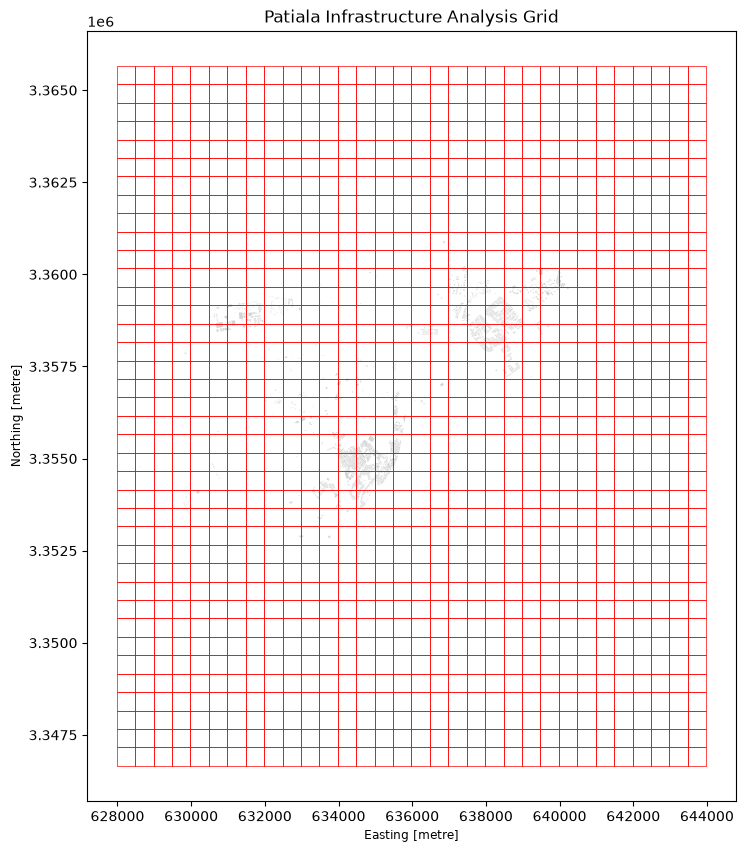

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

buildings_utm.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="none"
)

grid.boundary.plot(
    ax=ax,
    color="red",
    linewidth=0.5
)

ax.set_title("Patiala Infrastructure Analysis Grid")
plt.show()

In [11]:
print("WATER COLUMNS:")
print(water_utm.columns.tolist())

print("\nWATERWAY CATEGORIES:")
if "waterway" in water_utm.columns:
    print(water_utm["waterway"].value_counts(dropna=False))
else:
    print("No waterway column found")

print("\nROAD COLUMNS:")
print(roads_utm.columns.tolist())

print("\nBUILDING COLUMNS:")
print(buildings_utm.columns.tolist())

WATER COLUMNS:
['id', '@id', 'layer', 'tunnel', 'waterway', 'feature_category', 'source', 'length_m_approx', 'geometry']

WATERWAY CATEGORIES:
waterway
stream    5
canal     3
ditch     2
drain     1
Name: count, dtype: int64

ROAD COLUMNS:
['id', '@id', 'access', 'alt_name', 'bicycle', 'bridge', 'covered', 'crossing', 'crossing:markings', 'foot', 'footway', 'highway', 'horse', 'incline', 'junction', 'lane_markings', 'lanes', 'layer', 'maxspeed', 'motor_vehicle', 'motorroad', 'name', 'name:etymology:wikidata', 'oneway', 'ref', 'ref:old', 'service', 'surface', 'tunnel', 'wikidata', 'feature_category', 'road_type', 'source', 'length_m_approx', 'geometry']

BUILDING COLUMNS:
['id', '@id', 'addr:city', 'addr:city:pa', 'addr:district', 'addr:full', 'addr:housenumber', 'addr:place', 'addr:place:pa', 'addr:postcode', 'addr:state', 'addr:street', 'air_conditioning', 'amenity', 'architect', 'area', 'building', '@relations', 'building:levels', 'contact:facebook', 'cuisine', 'currency:INR', 'deli

In [12]:
# Create building centroids for assigning each building to one grid cell
building_points = buildings_utm.copy()
building_points["geometry"] = building_points.geometry.centroid

# Assign each building to a grid cell
building_join = gpd.sjoin(
    building_points,
    grid[["grid_id", "geometry"]],
    how="inner",
    predicate="within"
)

# Calculate building count and total footprint area
building_features = building_join.groupby("grid_id").agg(
    building_count=("id", "count"),
    building_area_m2=("area_m2_approx", "sum")
).reset_index()

print(building_features.head())

   grid_id  building_count  building_area_m2
0       55               1            412.61
1      128              10           1657.73
2      129              23           4488.97
3      137               1           1369.96
4      167               5           6005.51


In [13]:
road_features = []

for _, cell in grid.iterrows():

    # Find roads intersecting this cell
    indices = roads_utm.sindex.query(
        cell.geometry,
        predicate="intersects"
    )

    total_length = 0

    for idx in indices:
        road = roads_utm.geometry.iloc[idx]

        clipped_road = road.intersection(cell.geometry)

        if not clipped_road.is_empty:
            total_length += clipped_road.length

    road_features.append({
        "grid_id": cell["grid_id"],
        "road_length_m": total_length
    })

road_features = pd.DataFrame(road_features)

print(road_features.head())

   grid_id  road_length_m
0        1            0.0
1        2            0.0
2        3            0.0
3        4            0.0
4        5            0.0


In [14]:
water_features = []

water_categories = ["drain", "ditch", "canal", "stream"]

for _, cell in grid.iterrows():

    indices = water_utm.sindex.query(
        cell.geometry,
        predicate="intersects"
    )

    category_lengths = {
        category: 0.0 for category in water_categories
    }

    for idx in indices:

        feature = water_utm.iloc[idx]
        category = feature["waterway"]

        if category in category_lengths:

            clipped_feature = feature.geometry.intersection(
                cell.geometry
            )

            if not clipped_feature.is_empty:
                category_lengths[category] += clipped_feature.length

    water_features.append({
        "grid_id": cell["grid_id"],
        "drain_length_m": category_lengths["drain"],
        "ditch_length_m": category_lengths["ditch"],
        "canal_length_m": category_lengths["canal"],
        "stream_length_m": category_lengths["stream"]
    })

water_features = pd.DataFrame(water_features)

print(water_features.head())

   grid_id  drain_length_m  ditch_length_m  canal_length_m  stream_length_m
0        1             0.0             0.0             0.0       711.873412
1        2             0.0             0.0             0.0       341.659832
2        3             0.0             0.0             0.0         0.000000
3        4             0.0             0.0             0.0         0.000000
4        5             0.0             0.0             0.0         0.000000


In [15]:
# Start with grid IDs
grid_features = grid[["grid_id", "geometry"]].copy()

# Merge building, road and water features
grid_features = grid_features.merge(
    building_features, on="grid_id", how="left"
)

grid_features = grid_features.merge(
    road_features, on="grid_id", how="left"
)

grid_features = grid_features.merge(
    water_features, on="grid_id", how="left"
)

# Replace missing feature values with zero
feature_columns = [
    "building_count",
    "building_area_m2",
    "road_length_m",
    "drain_length_m",
    "ditch_length_m",
    "canal_length_m",
    "stream_length_m"
]

grid_features[feature_columns] = (
    grid_features[feature_columns].fillna(0)
)

print("Final dataset shape:", grid_features.shape)
print(grid_features.head())

Final dataset shape: (1216, 9)
   grid_id                                           geometry  building_count  \
0        1  POLYGON ((628480.466 3346660.54, 628480.466 33...             0.0   
1        2  POLYGON ((628480.466 3347160.54, 628480.466 33...             0.0   
2        3  POLYGON ((628480.466 3347660.54, 628480.466 33...             0.0   
3        4  POLYGON ((628480.466 3348160.54, 628480.466 33...             0.0   
4        5  POLYGON ((628480.466 3348660.54, 628480.466 33...             0.0   

   building_area_m2  road_length_m  drain_length_m  ditch_length_m  \
0               0.0            0.0             0.0             0.0   
1               0.0            0.0             0.0             0.0   
2               0.0            0.0             0.0             0.0   
3               0.0            0.0             0.0             0.0   
4               0.0            0.0             0.0             0.0   

   canal_length_m  stream_length_m  
0             0.0       

In [16]:
print("Dataset shape:", grid_features.shape)

print("\nColumn names:")
print(grid_features.columns.tolist())

print("\nMissing values:")
print(grid_features.isnull().sum())

print("\nStatistical summary:")
print(grid_features.drop(columns="geometry").describe())

Dataset shape: (1216, 9)

Column names:
['grid_id', 'geometry', 'building_count', 'building_area_m2', 'road_length_m', 'drain_length_m', 'ditch_length_m', 'canal_length_m', 'stream_length_m']

Missing values:
grid_id             0
geometry            0
building_count      0
building_area_m2    0
road_length_m       0
drain_length_m      0
ditch_length_m      0
canal_length_m      0
stream_length_m     0
dtype: int64

Statistical summary:
           grid_id  building_count  building_area_m2  road_length_m  \
count  1216.000000     1216.000000       1216.000000    1216.000000   
mean    608.500000        4.561678       1736.969005    1308.591031   
std     351.173272       31.730415       9166.522199    2203.939598   
min       1.000000        0.000000          0.000000       0.000000   
25%     304.750000        0.000000          0.000000       0.000000   
50%     608.500000        0.000000          0.000000       0.000000   
75%     912.250000        0.000000          0.000000    2013.

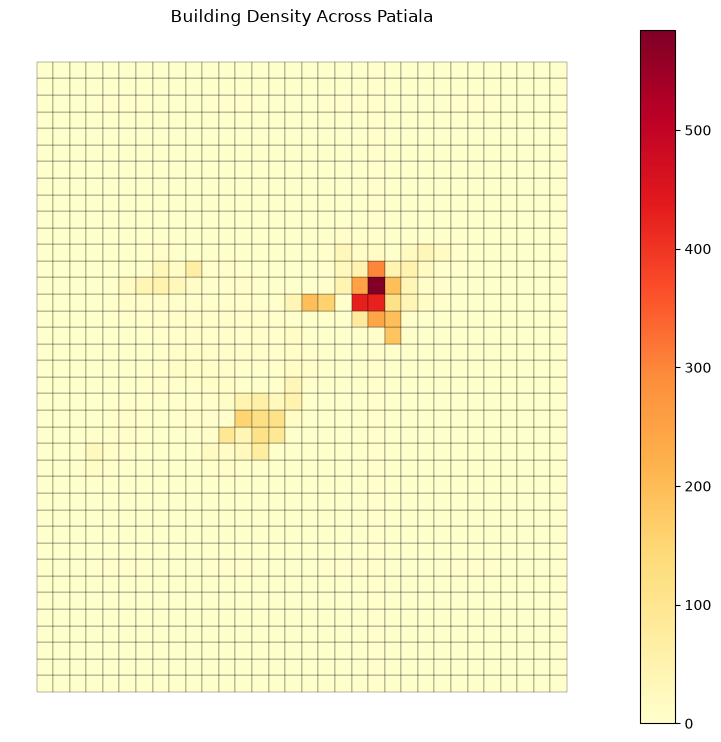

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

grid_features.plot(
    column="building_count",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Building Density Across Patiala")
ax.set_axis_off()

plt.show()

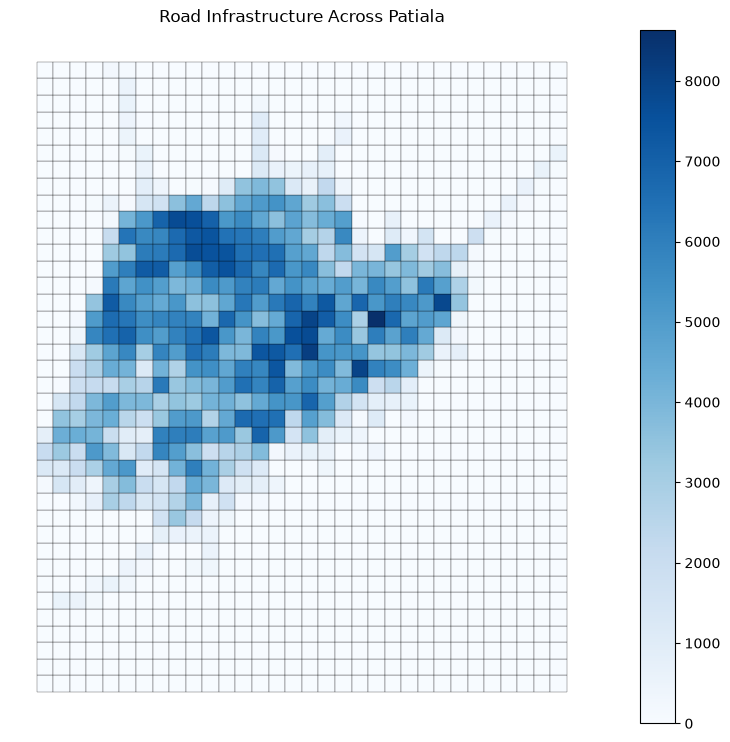

In [18]:
fig, ax = plt.subplots(figsize=(12, 9))

grid_features.plot(
    column="road_length_m",
    cmap="Blues",
    legend=True,
    edgecolor="black",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Road Infrastructure Across Patiala")
ax.set_axis_off()

plt.show()

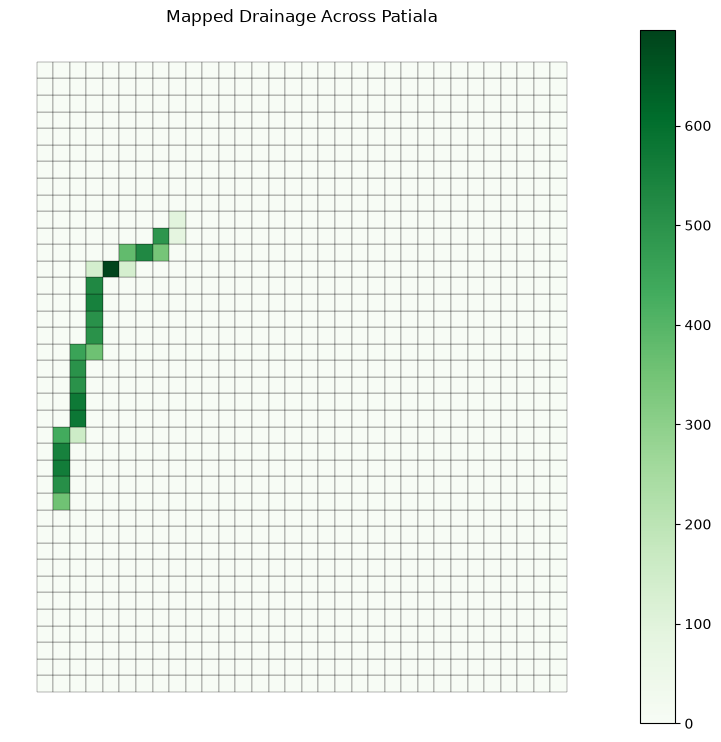

In [19]:
fig, ax = plt.subplots(figsize=(12, 9))

grid_features.plot(
    column="drain_length_m",
    cmap="Greens",
    legend=True,
    edgecolor="black",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Mapped Drainage Across Patiala")
ax.set_axis_off()

plt.show()

In [20]:
import os

os.makedirs("../data/processed", exist_ok=True)

grid_features.to_file(
    "../data/processed/patiala_grid_features.geojson",
    driver="GeoJSON"
)

grid_features.drop(columns="geometry").to_csv(
    "../data/processed/patiala_grid_features.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [21]:
# Each grid cell is 500 m x 500 m = 250,000 m²
grid_area_km2 = 0.25
grid_area_m2 = 250000

# Building density
grid_features["building_density_km2"] = (
    grid_features["building_count"] / grid_area_km2
)

# Road density
grid_features["road_density_km_km2"] = (
    grid_features["road_length_m"] / 1000 / grid_area_km2
)

# Drainage density
grid_features["drainage_density_km_km2"] = (
    grid_features["drain_length_m"] / 1000 / grid_area_km2
)

# Percentage of land covered by building footprints
grid_features["building_coverage_pct"] = (
    grid_features["building_area_m2"] / grid_area_m2
) * 100

print(grid_features[[
    "grid_id",
    "building_density_km2",
    "road_density_km_km2",
    "drainage_density_km_km2",
    "building_coverage_pct"
]].head())

   grid_id  building_density_km2  road_density_km_km2  \
0        1                   0.0                  0.0   
1        2                   0.0                  0.0   
2        3                   0.0                  0.0   
3        4                   0.0                  0.0   
4        5                   0.0                  0.0   

   drainage_density_km_km2  building_coverage_pct  
0                      0.0                    0.0  
1                      0.0                    0.0  
2                      0.0                    0.0  
3                      0.0                    0.0  
4                      0.0                    0.0  


In [22]:
# Divide building density into quartiles
building_threshold = grid_features["building_density_km2"].quantile(0.75)

# Identify areas with relatively high building density
grid_features["high_building_density"] = (
    grid_features["building_density_km2"] >= building_threshold
)

# Identify cells with no mapped drain
grid_features["no_mapped_drain"] = (
    grid_features["drain_length_m"] == 0
)

# Initial screening flag
grid_features["drainage_screening_flag"] = (
    grid_features["high_building_density"] &
    grid_features["no_mapped_drain"]
)

print("High-density threshold:", building_threshold)

print("\nScreening results:")
print(grid_features["drainage_screening_flag"].value_counts())

print("\nPotential areas for further investigation:")
print(
    grid_features.loc[
        grid_features["drainage_screening_flag"],
        ["grid_id", "building_density_km2", "drain_length_m"]
    ].head(10)
)

High-density threshold: 0.0

Screening results:
drainage_screening_flag
True     1191
False      25
Name: count, dtype: int64

Potential areas for further investigation:
   grid_id  building_density_km2  drain_length_m
0        1                   0.0             0.0
1        2                   0.0             0.0
2        3                   0.0             0.0
3        4                   0.0             0.0
4        5                   0.0             0.0
5        6                   0.0             0.0
6        7                   0.0             0.0
7        8                   0.0             0.0
8        9                   0.0             0.0
9       10                   0.0             0.0


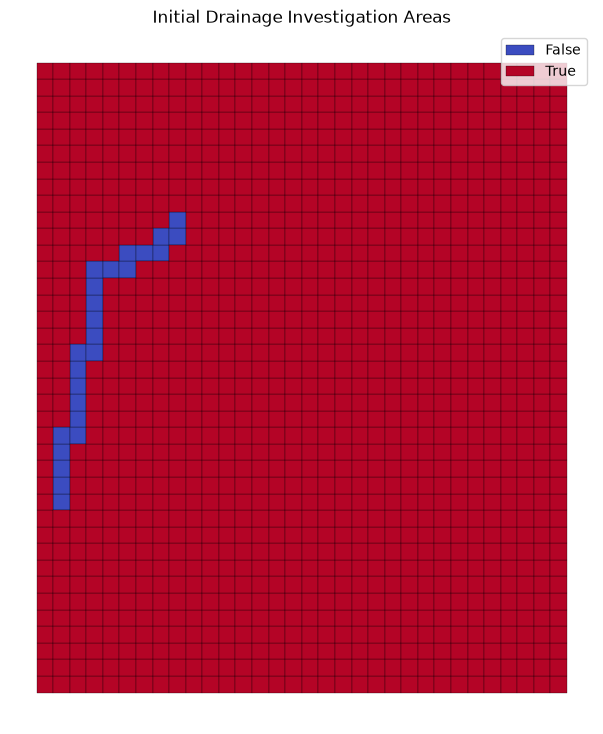

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

grid_features.plot(
    column="drainage_screening_flag",
    categorical=True,
    cmap="coolwarm",
    legend=True,
    edgecolor="black",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Initial Drainage Investigation Areas")
ax.set_axis_off()

plt.show()

In [24]:
grid_features.to_file(
    "../data/processed/patiala_grid_features.geojson",
    driver="GeoJSON"
)

grid_features.drop(columns="geometry").to_csv(
    "../data/processed/patiala_grid_features.csv",
    index=False
)

print("Updated feature-engineered dataset saved!")

Updated feature-engineered dataset saved!


In [25]:
features_to_check = [
    "building_count",
    "building_area_m2",
    "road_length_m",
    "drain_length_m",
    "ditch_length_m",
    "canal_length_m",
    "stream_length_m"
]

print("Total grid cells:", len(grid_features))

print("\nNon-zero cells:")
print((grid_features[features_to_check] > 0).sum())

print("\nFeature statistics:")
print(grid_features[features_to_check].describe())

Total grid cells: 1216

Non-zero cells:
building_count      156
building_area_m2    156
road_length_m       460
drain_length_m       25
ditch_length_m       10
canal_length_m       20
stream_length_m      68
dtype: int64

Feature statistics:
       building_count  building_area_m2  road_length_m  drain_length_m  \
count     1216.000000       1216.000000    1216.000000     1216.000000   
mean         4.561678       1736.969005    1308.591031        8.645132   
std         31.730415       9166.522199    2203.939598       64.372007   
min          0.000000          0.000000       0.000000        0.000000   
25%          0.000000          0.000000       0.000000        0.000000   
50%          0.000000          0.000000       0.000000        0.000000   
75%          0.000000          0.000000    2013.486510        0.000000   
max        584.000000     120350.330000    8629.158154      695.499776   

       ditch_length_m  canal_length_m  stream_length_m  
count     1216.000000     1216.000

In [26]:
import numpy as np
import pandas as pd

# Select infrastructure features
X = grid_features[features_to_check].copy()

# Handle missing and infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(0)

# Reduce the effect of very large values
X = np.log1p(X)

print("ML feature matrix shape:", X.shape)
print(X.head())

ML feature matrix shape: (1216, 7)
   building_count  building_area_m2  road_length_m  drain_length_m  \
0             0.0               0.0            0.0             0.0   
1             0.0               0.0            0.0             0.0   
2             0.0               0.0            0.0             0.0   
3             0.0               0.0            0.0             0.0   
4             0.0               0.0            0.0             0.0   

   ditch_length_m  canal_length_m  stream_length_m  
0             0.0             0.0         6.569304  
1             0.0             0.0         5.836738  
2             0.0             0.0         0.000000  
3             0.0             0.0         0.000000  
4             0.0             0.0         0.000000  


In [27]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create the model
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

# Train and predict
grid_features["anomaly_prediction"] = model.fit_predict(X_scaled)

# Convert predictions into readable labels
grid_features["anomaly_status"] = (
    grid_features["anomaly_prediction"]
    .map({1: "Normal", -1: "Anomaly"})
)

print("Model training completed!")

print("\nPrediction results:")
print(grid_features["anomaly_status"].value_counts())

Model training completed!

Prediction results:
anomaly_status
Normal     1155
Anomaly      61
Name: count, dtype: int64


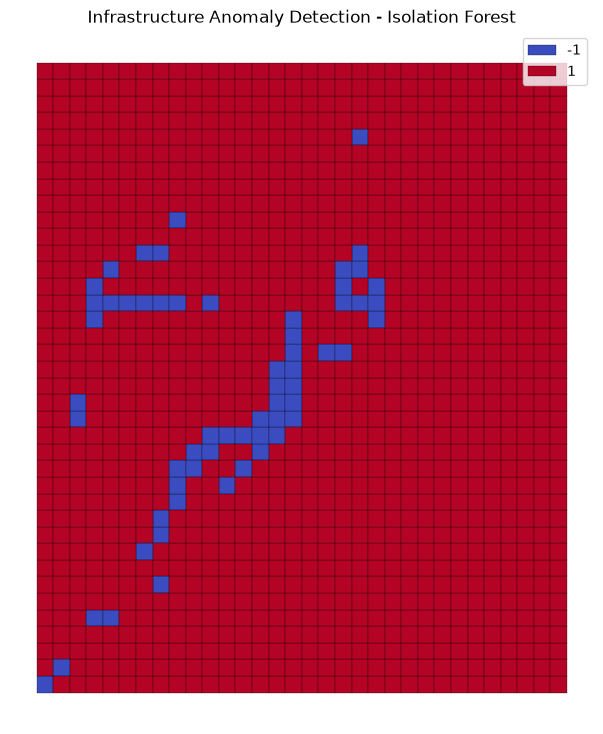

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

grid_features.plot(
    column="anomaly_prediction",
    categorical=True,
    cmap="coolwarm",
    legend=True,
    edgecolor="black",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Infrastructure Anomaly Detection - Isolation Forest")
ax.set_axis_off()

plt.show()

In [29]:
anomaly_results = grid_features[
    grid_features["anomaly_status"] == "Anomaly"
][[
    "grid_id",
    "building_count",
    "road_length_m",
    "drain_length_m",
    "ditch_length_m",
    "canal_length_m",
    "stream_length_m"
]]

print(anomaly_results)

     grid_id  building_count  road_length_m  drain_length_m  ditch_length_m  \
0          1             0.0       0.000000        0.000000             0.0   
39        40             0.0       0.000000        0.000000             0.0   
92        93             0.0    3002.591567      578.604958             0.0   
93        94             0.0    2277.254846      572.623997             0.0   
118      119             0.0       0.000000        0.000000             0.0   
..       ...             ...            ...             ...             ...   
748      749            10.0    1602.404834        0.000000             0.0   
755      756             0.0       0.000000        0.000000             0.0   
782      783           246.0    8629.158154        0.000000             0.0   
783      784           428.0    5198.862807        0.000000             0.0   
784      785           584.0    5693.564578        0.000000             0.0   

     canal_length_m  stream_length_m  
0           

In [30]:
# Calculate anomaly scores
grid_features["anomaly_score"] = model.decision_function(X_scaled)

# Lower scores indicate more unusual observations
grid_features["anomaly_rank"] = (
    grid_features["anomaly_score"]
    .rank(method="min", ascending=True)
    .astype(int)
)

# Display the 15 most unusual cells
top_anomalies = grid_features.sort_values(
    by="anomaly_score",
    ascending=True
)

print(top_anomalies[[
    "grid_id",
    "anomaly_status",
    "anomaly_score",
    "building_count",
    "road_length_m",
    "drain_length_m",
    "ditch_length_m",
    "canal_length_m",
    "stream_length_m"
]].head(15))

     grid_id anomaly_status  anomaly_score  building_count  road_length_m  \
510      511        Anomaly      -0.120851           122.0    6531.288845   
548      549        Anomaly      -0.118361           115.0    6480.824622   
509      510        Anomaly      -0.104456           116.0    6888.375724   
433      434        Anomaly      -0.103025            98.0    5060.023985   
471      472        Anomaly      -0.102877            38.0    3332.884282   
394      395        Anomaly      -0.087729            19.0    1875.659815   
549      550        Anomaly      -0.085866            25.0    5292.737885   
137      138        Anomaly      -0.084091             0.0    3453.914677   
547      548        Anomaly      -0.073580            92.0    5100.878802   
356      357        Anomaly      -0.067404             2.0    3663.633939   
550      551        Anomaly      -0.066041             1.0    6922.148105   
508      509        Anomaly      -0.062827            74.0    3834.135989   

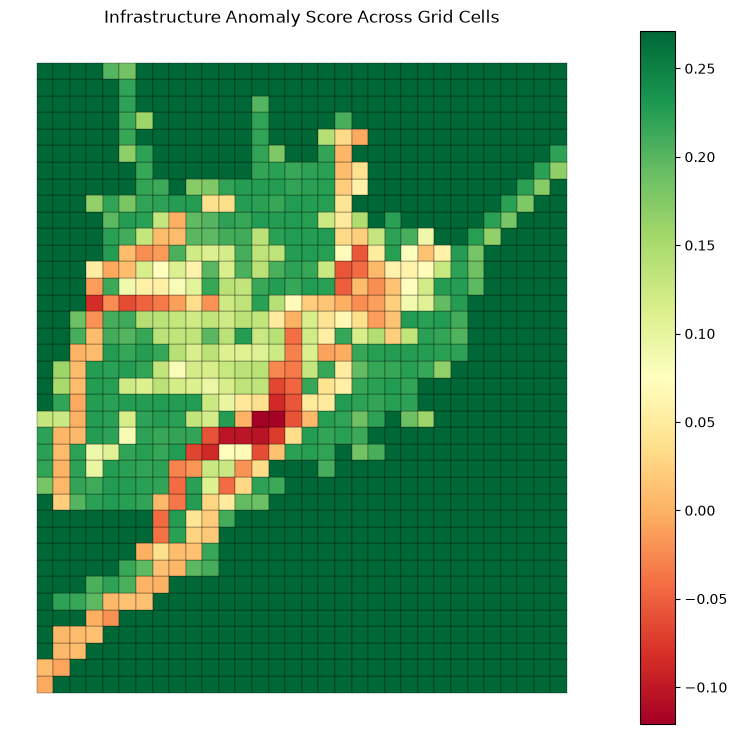

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

grid_features.plot(
    column="anomaly_score",
    cmap="RdYlGn",
    legend=True,
    edgecolor="black",
    linewidth=0.2,
    ax=ax
)

ax.set_title("Infrastructure Anomaly Score Across Grid Cells")
ax.set_axis_off()

plt.show()

In [32]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/drainage_isolation_forest.pkl")
joblib.dump(scaler, "../models/drainage_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [33]:
os.makedirs("../data/processed", exist_ok=True)

grid_features.to_file(
    "../data/processed/patiala_drainage_anomaly_results.geojson",
    driver="GeoJSON"
)

grid_features.drop(columns="geometry").to_csv(
    "../data/processed/patiala_drainage_anomaly_results.csv",
    index=False
)

print("Anomaly detection results exported successfully!")

Anomaly detection results exported successfully!


In [34]:
import geopandas as gpd
import os

file_path = "../data/processed/patiala_grid_features.geojson"

grid_features = gpd.read_file(file_path)

print("Grid features loaded successfully!")
print("Shape:", grid_features.shape)
print(grid_features.head())

Grid features loaded successfully!
Shape: (1216, 16)
   grid_id  building_count  building_area_m2  road_length_m  drain_length_m  \
0        1             0.0               0.0            0.0             0.0   
1        2             0.0               0.0            0.0             0.0   
2        3             0.0               0.0            0.0             0.0   
3        4             0.0               0.0            0.0             0.0   
4        5             0.0               0.0            0.0             0.0   

   ditch_length_m  canal_length_m  stream_length_m  building_density_km2  \
0             0.0             0.0       711.873412                   0.0   
1             0.0             0.0       341.659832                   0.0   
2             0.0             0.0         0.000000                   0.0   
3             0.0             0.0         0.000000                   0.0   
4             0.0             0.0         0.000000                   0.0   

   road_density

In [35]:
print(grid_features.columns.tolist())

['grid_id', 'building_count', 'building_area_m2', 'road_length_m', 'drain_length_m', 'ditch_length_m', 'canal_length_m', 'stream_length_m', 'building_density_km2', 'road_density_km_km2', 'drainage_density_km_km2', 'building_coverage_pct', 'high_building_density', 'no_mapped_drain', 'drainage_screening_flag', 'geometry']


In [36]:
# Create a copy of the final grid dataset
drainage_assessment = grid_features.copy()

# Calculate the 75th percentile of building density
building_threshold = drainage_assessment[
    "building_density_km2"
].quantile(0.75)

# Identify relatively high-density areas
drainage_assessment["high_building_density"] = (
    drainage_assessment["building_density_km2"]
    >= building_threshold
)

# Identify areas with no mapped drain
drainage_assessment["no_mapped_drain"] = (
    drainage_assessment["drain_length_m"] == 0
)

# Identify areas with no mapped drain but relatively high building density
drainage_assessment["requires_drainage_investigation"] = (
    drainage_assessment["high_building_density"]
    & drainage_assessment["no_mapped_drain"]
)

print("Drainage assessment completed!")

print(
    drainage_assessment[
        "requires_drainage_investigation"
    ].value_counts()
)

Drainage assessment completed!
requires_drainage_investigation
True     1191
False      25
Name: count, dtype: int64


In [37]:
def generate_recommendation(row):

    if row["requires_drainage_investigation"]:
        return (
            "Verify drainage network coverage and conduct "
            "a field inspection"
        )

    elif row["drain_length_m"] > 0:
        return "Review mapped drainage coverage and condition"

    else:
        return "Collect additional drainage infrastructure data"


drainage_assessment["recommendation"] = (
    drainage_assessment.apply(
        generate_recommendation,
        axis=1
    )
)

print(
    drainage_assessment[
        [
            "grid_id",
            "building_density_km2",
            "drain_length_m",
            "recommendation"
        ]
    ].head(15)
)

    grid_id  building_density_km2  drain_length_m  \
0         1                   0.0             0.0   
1         2                   0.0             0.0   
2         3                   0.0             0.0   
3         4                   0.0             0.0   
4         5                   0.0             0.0   
5         6                   0.0             0.0   
6         7                   0.0             0.0   
7         8                   0.0             0.0   
8         9                   0.0             0.0   
9        10                   0.0             0.0   
10       11                   0.0             0.0   
11       12                   0.0             0.0   
12       13                   0.0             0.0   
13       14                   0.0             0.0   
14       15                   0.0             0.0   

                                       recommendation  
0   Verify drainage network coverage and conduct a...  
1   Verify drainage network coverage an

In [38]:
import pandas as pd
import numpy as np

def generate_recommendation(row):

    if row["requires_drainage_investigation"]:
        return pd.Series({
            "priority": "High",
            "recommendation": "Verify drainage network coverage and conduct field inspection",
            "reason": "High mapped building density with no mapped drain"
        })

    elif row["drain_length_m"] > 0:
        return pd.Series({
            "priority": "Review",
            "recommendation": "Review mapped drainage coverage and condition",
            "reason": "A mapped drain is present; its condition and capacity are unknown"
        })

    else:
        return pd.Series({
            "priority": "Data Required",
            "recommendation": "Collect additional drainage infrastructure data",
            "reason": "No drain is mapped in the current dataset"
        })


# Generate recommendations
drainage_assessment[
    ["priority", "recommendation", "reason"]
] = drainage_assessment.apply(
    generate_recommendation,
    axis=1
)

# Display results
print(
    drainage_assessment[
        [
            "grid_id",
            "building_density_km2",
            "drain_length_m",
            "priority",
            "recommendation",
            "reason"
        ]
    ].head(15)
)

print("\nPriority distribution:")
print(drainage_assessment["priority"].value_counts())

    grid_id  building_density_km2  drain_length_m priority  \
0         1                   0.0             0.0     High   
1         2                   0.0             0.0     High   
2         3                   0.0             0.0     High   
3         4                   0.0             0.0     High   
4         5                   0.0             0.0     High   
5         6                   0.0             0.0     High   
6         7                   0.0             0.0     High   
7         8                   0.0             0.0     High   
8         9                   0.0             0.0     High   
9        10                   0.0             0.0     High   
10       11                   0.0             0.0     High   
11       12                   0.0             0.0     High   
12       13                   0.0             0.0     High   
13       14                   0.0             0.0     High   
14       15                   0.0             0.0     High   

       

In [39]:
import os

os.makedirs("../data/processed", exist_ok=True)

drainage_assessment.drop(columns="geometry").to_csv(
    "../data/processed/drainage_recommendations.csv",
    index=False
)

drainage_assessment.to_file(
    "../data/processed/drainage_recommendations.geojson",
    driver="GeoJSON"
)

print("Recommendations saved successfully!")

Recommendations saved successfully!


In [42]:
import sys
print(sys.executable)

c:\Users\Sanna Sharma\AppData\Local\Programs\Python\Python314\python.exe


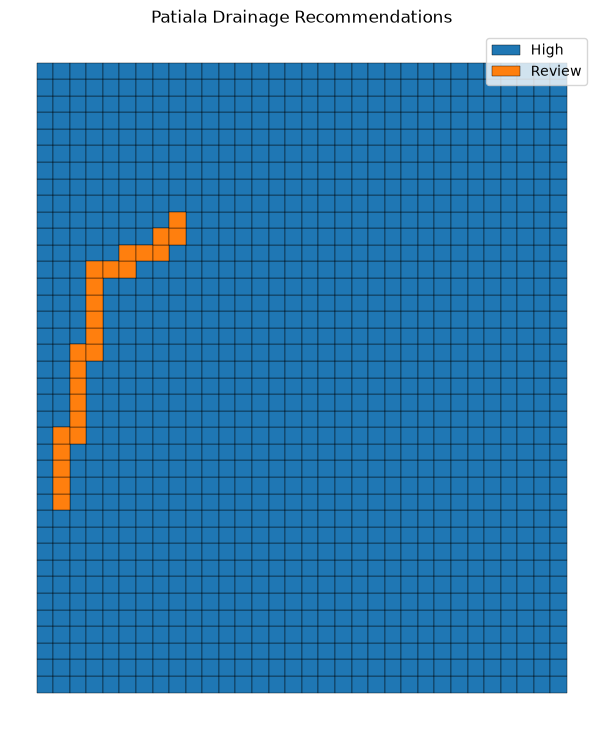

In [43]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

drainage_assessment.plot(
    column="priority",
    categorical=True,
    legend=True,
    edgecolor="black",
    linewidth=0.3,
    ax=ax
)

ax.set_title("Patiala Drainage Recommendations")
ax.set_axis_off()

plt.show()

In [44]:
drainage_assessment.to_file(
    "../data/processed/drainage_recommendations.geojson",
    driver="GeoJSON"
)

drainage_assessment.drop(
    columns="geometry"
).to_csv(
    "../data/processed/drainage_recommendations.csv",
    index=False
)

print("Recommendation files saved successfully!")

Recommendation files saved successfully!


In [45]:
print("Total grid cells:", len(drainage_assessment))

print("\nPriority distribution:")
print(drainage_assessment["priority"].value_counts())

print("\nMissing values:")
print(drainage_assessment.isnull().sum())

print("\nRecommendation examples:")
print(
    drainage_assessment[
        ["grid_id", "priority", "recommendation", "reason"]
    ].head(10)
)

Total grid cells: 1216

Priority distribution:
priority
High      1191
Review      25
Name: count, dtype: int64

Missing values:
grid_id                            0
building_count                     0
building_area_m2                   0
road_length_m                      0
drain_length_m                     0
ditch_length_m                     0
canal_length_m                     0
stream_length_m                    0
building_density_km2               0
road_density_km_km2                0
drainage_density_km_km2            0
building_coverage_pct              0
high_building_density              0
no_mapped_drain                    0
drainage_screening_flag            0
geometry                           0
requires_drainage_investigation    0
recommendation                     0
priority                           0
reason                             0
dtype: int64

Recommendation examples:
   grid_id priority                                     recommendation  \
0        1     Hig

In [46]:
print("Total grid cells:", len(drainage_assessment))

print("\nPriority distribution:")
print(drainage_assessment["priority"].value_counts())

print("\nMissing values:")
print(drainage_assessment.isnull().sum())

print("\nRecommendation examples:")
print(
    drainage_assessment[
        ["grid_id", "priority", "recommendation", "reason"]
    ].head(10)
)

Total grid cells: 1216

Priority distribution:
priority
High      1191
Review      25
Name: count, dtype: int64

Missing values:
grid_id                            0
building_count                     0
building_area_m2                   0
road_length_m                      0
drain_length_m                     0
ditch_length_m                     0
canal_length_m                     0
stream_length_m                    0
building_density_km2               0
road_density_km_km2                0
drainage_density_km_km2            0
building_coverage_pct              0
high_building_density              0
no_mapped_drain                    0
drainage_screening_flag            0
geometry                           0
requires_drainage_investigation    0
recommendation                     0
priority                           0
reason                             0
dtype: int64

Recommendation examples:
   grid_id priority                                     recommendation  \
0        1     Hig